# M03-4 | Shared qparams: SharedQuantizationSpec and Implicit Sharing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m03_quantizer_api/04_shared_and_implicit_sharing.ipynb)

To do integer addition (or concat) on two int8 tensors, they must be on the same scale: integers with different scales can't be added directly, and the hardware would have to rescale one of them first.
So some backends require **all inputs and outputs of add and cat to share one set of (scale, zero point)**.

In PT2E, "sharing qparams" means making several positions share **the same observer instance**: this observer sees the values at all the positions, computes one scale, and everyone uses it.
Sharing comes from two sources:

- **Explicit**: the annotation's spec is `SharedQuantizationSpec(some position)`, meaning "use the same observer as that position".
- **Implicit**: when two annotations on the same tensor have identical attributes, `prepare_pt2e` merges them into one observer automatically. Mentioned in M03-1 section C.

Sections:

- **A.** Explicit sharing: make the inputs and output of add share one set of qparams.
- **B.** Implicit sharing: when the same tensor has both an output annotation and an edge annotation, when they merge and when they chain.


In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import the course's common/
    os.chdir(f"{repo}/en/m03_quantizer_api")

In [2]:
import copy

import torch
from torch.fx import Node

from common.graph_utils import observer_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    MovingAverageMinMaxObserver,
    QuantizationSpec,
    Quantizer,
    SharedQuantizationSpec,
    annotate_input_qspec_map,
    annotate_output_qspec,
    convert_pt2e,
    export_module,
    prepare_pt2e,
    quiet,
)
from common.qspecs import act_spec
from common.viz import draw, table

quiet()
_ = torch.manual_seed(0)
ADD = torch.ops.aten.add.Tensor

## A. Explicit Sharing: SharedQuantizationSpec

`AddQuantizer` finds all adds by `node.target`. The first input edge uses an ordinary spec; when `share=True`, the remaining input edges and the output all get
`SharedQuantizationSpec((first input, add))`: the argument is a **position**, an edge written as `(producer, consumer)`, and a node's output given as the node itself.

Only activations need annotations, so two kinds of input must be excluded: the Python scalar in `add(x, 1.0)` (not a `Node`, so it can't be a key of `input_qspec_map`),
and the model constant in `add(x, self.b)` (`get_attr`). In `add(x, x)` both inputs are the same node and need de-duplication.


In [3]:
class AddQuantizer(Quantizer):
    def __init__(self, share: bool):
        self.share = share

    def annotate(self, model):
        for node in model.graph.nodes:
            if node.op != "call_function" or node.target != ADD:
                continue
            ann = node.meta.get(ANNOTATION_KEY)
            if ann is not None and ann._annotated:
                continue
            inputs = list(dict.fromkeys(a for a in node.args[:2] if isinstance(a, Node) and a.op != "get_attr"))
            if not inputs:
                continue
            spec = act_spec()
            annotate_input_qspec_map(node, inputs[0], spec)
            rest = SharedQuantizationSpec((inputs[0], node)) if self.share else spec  # shares with "first input → add"
            for other in inputs[1:]:
                annotate_input_qspec_map(node, other, rest)
            annotate_output_qspec(node, rest)
            node.meta[ANNOTATION_KEY]._annotated = True
        return model

    def validate(self, model):
        pass

The first model has a single add, with the ranges of the two inputs deliberately very different (`b` is 5 times `a`). Prepare once with sharing and once without, calibrate, and the observers in the graph will show the computed scales:


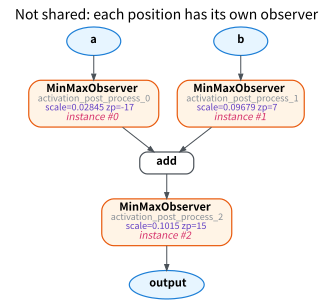

In [4]:
class AddOnly(torch.nn.Module):
    def forward(self, a, b):
        return a + b


def make_inputs():
    return torch.randn(4, 8), torch.randn(4, 8) * 5


def prepare_add(gm, share, make_inputs):
    prepared = prepare_pt2e(copy.deepcopy(gm), AddQuantizer(share))
    with torch.no_grad():
        for _ in range(8):
            prepared(*make_inputs())
    return prepared


def instance_notes(prepared):
    """Label each observer node with which observer instance it uses."""
    number: dict[int, int] = {}
    return {n.name: f"instance #{number.setdefault(id(mod), len(number))}" for n, mod in observer_nodes(prepared)}


gm_add = export_module(AddOnly(), make_inputs())
separate = prepare_add(gm_add, False, make_inputs)
draw(separate, notes=instance_notes(separate), title="Not shared: each position has its own observer")

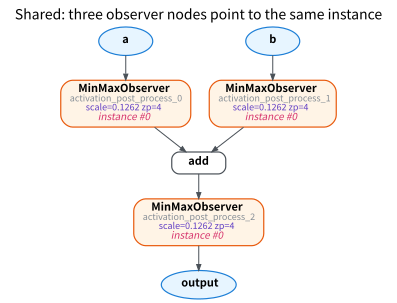

In [5]:
shared = prepare_add(gm_add, True, make_inputs)
draw(shared, notes=instance_notes(shared), title="Shared: three observer nodes point to the same instance")

In [6]:
def summary(prepared):
    mods = [mod for _, mod in observer_nodes(prepared)]
    scales = sorted({round(float(m.calculate_qparams()[0]), 6) for m in mods})
    return len(mods), len({id(m) for m in mods}), scales


for title, p in [("Not shared", separate), ("Shared", shared)]:
    n_nodes, n_instances, scales = summary(p)
    print(f"{title}: {n_nodes} observer nodes, {n_instances} instances, scale {scales}")
assert summary(separate)[1] == 3 and summary(shared)[1] == 1

Not shared: 3 observer nodes, 3 instances, scale [0.028452, 0.09679, 0.101465]
Shared: 3 observer nodes, 1 instances, scale [0.126223]


- Without sharing: the three positions compute their own scales; `b` has a large range, so its scale is large too.
- With sharing: the graph still has three observer nodes (every position must be observed), but they are the same observer instance. This instance sees all the values of `a`, `b` and the output, and computes one scale covering all of them.

The same `AddQuantizer` doesn't need to know what the model looks like. Switch to the residual model (the inputs of add are the conv's output and the skip connection's `x`) and draw only the area around add:


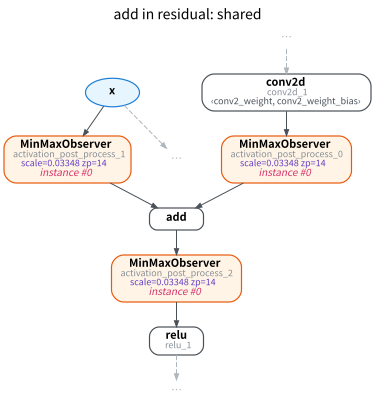

In [7]:
gm_res = export_module(get_model("residual").eval(), example_inputs(4))
res_shared = prepare_add(gm_res, True, lambda: (torch.randn(4, 3, 16, 16),))
draw(res_shared, focus="add", hops=2, notes=instance_notes(res_shared), title="add in residual: shared")

In [8]:
n_nodes, n_instances, _ = summary(res_shared)
print(f"{n_nodes} observer nodes, {n_instances} instances")
assert n_instances == 1 and n_nodes == 3

3 observer nodes, 1 instances


## B. Implicit Sharing: Output Annotation + Edge Annotation

M03-1 section C showed that one tensor can have an **output annotation** (affecting all consumers) and also an **edge annotation** (affecting only one consumer).
What happens when both are attached?

Use the `cat_pool` model (the input `x` feeds both `conv2d` and `conv2d_1`). `TwoLabelQuantizer` attaches spec A to the output of `x`, and spec B to the edge `x → conv2d_1`.
It is written for this experiment by naming nodes, so the node names only fit `cat_pool`. `allow_implicit_sharing` is a field of `QuantizationAnnotation` (default `True`); setting it to `False` turns merging off.


In [9]:
class TwoLabelQuantizer(Quantizer):
    def __init__(self, spec_a, spec_b, implicit=True):
        self.spec_a, self.spec_b, self.implicit = spec_a, spec_b, implicit

    def annotate(self, model):
        nodes = {n.name: n for n in model.graph.nodes}
        annotate_output_qspec(nodes["x"], self.spec_a)
        annotate_input_qspec_map(nodes["conv2d_1"], nodes["x"], self.spec_b)
        nodes["conv2d_1"].meta[ANNOTATION_KEY].allow_implicit_sharing = self.implicit
        return model

    def validate(self, model):
        pass

Spec B in the four cases:


In [10]:
a = act_spec()  # int8 per-tensor affine [-128, 127], MinMaxObserver
different = QuantizationSpec(  # qscheme and integer range both differ from A
    dtype=torch.int8, quant_min=-127, quant_max=127, qscheme=torch.per_tensor_symmetric,
    observer_or_fake_quant_ctr=a.observer_or_fake_quant_ctr,
)
other_observer = QuantizationSpec(  # quantization attributes identical to A; only the observer class differs
    dtype=a.dtype, quant_min=a.quant_min, quant_max=a.quant_max, qscheme=a.qscheme,
    observer_or_fake_quant_ctr=MovingAverageMinMaxObserver,
)
cases = [
    ("B differs from A in attributes", TwoLabelQuantizer(a, different)),
    ("B has the same attributes as A", TwoLabelQuantizer(a, a)),
    ("same attributes, but allow_implicit_sharing=False", TwoLabelQuantizer(a, a, implicit=False)),
    ("B differs from A only in observer class", TwoLabelQuantizer(a, other_observer)),
]

For each case, prepare, calibrate and convert, then print what `x` passes through on its way to `conv2d_1` (obs = observer, q/dq = quantize/dequantize):


In [11]:
def path_to(gm, consumer):
    """The nodes x passes through, in order, on its way to the consumer."""
    steps, src = [], next(n for n in gm.graph.nodes if n.name == consumer).args[0]
    while src.op != "placeholder":
        target = str(src.target)
        steps.append("obs" if src.op == "call_module" else "dq" if "dequantize" in target else "q")
        src = src.args[0]
    return " → ".join(["x", *reversed(steps), consumer])


gm_cat = export_module(get_model("cat_pool").eval(), example_inputs(4))
rows = []
for title, quantizer in cases:
    prepared = prepare_pt2e(copy.deepcopy(gm_cat), quantizer)
    obs = observer_nodes(prepared)
    kinds = ", ".join(sorted({type(m).__name__ for _, m in obs}))
    before = path_to(prepared, "conv2d_1")
    with torch.no_grad():
        for _ in range(4):
            prepared(torch.randn(4, 3, 16, 16))
    rows.append([title, len(obs), kinds, before, path_to(convert_pt2e(prepared), "conv2d_1")])
table(rows, ["case", "# observers", "observer classes", "after prepare", "after convert"])

case,# observers,observer classes,after prepare,after convert
B differs from A in attributes,2,MinMaxObserver,x → obs → obs → conv2d_1,x → q → dq → q → dq → conv2d_1
B has the same attributes as A,1,MinMaxObserver,x → obs → conv2d_1,x → q → dq → conv2d_1
"same attributes, but allow_implicit_sharing=False",2,MinMaxObserver,x → obs → obs → conv2d_1,x → q → dq → q → dq → conv2d_1
B differs from A only in observer class,1,MinMaxObserver,x → obs → conv2d_1,x → q → dq → conv2d_1


In [12]:
assert [r[1] for r in rows] == [2, 1, 2, 1]
assert rows[0][4] == "x → q → dq → q → dq → conv2d_1" and rows[1][4] == "x → q → dq → conv2d_1"
assert rows[3][2] == "MinMaxObserver"

1. **Different attributes: the two annotations chain.** `x` is first quantized by A, then quantized again by B; after convert there are two layers of q/dq, rounding twice. Neither overrides the other, and no error is raised.
2. **Identical attributes: automatically merged into one observer**, quantized only once. They are the same tensor anyway, so there is no need to quantize twice; this is implicit sharing.
3. **`allow_implicit_sharing=False`**: no merging, back to two chained observers. Once it is off, you are responsible for not quantizing the same tensor twice.
4. **What is compared is the quantization attributes (dtype, integer range, qscheme, ...), not the observer class.** When only the observer class differs, they also merge,
   and what remains is A's `MinMaxObserver`; the `MovingAverageMinMaxObserver` specified by B is silently ignored (in this graph A's annotation comes first in graph order).

To make the same tensor quantized only once: make the attributes of all annotations consistent, or explicitly point to the same position with `SharedQuantizationSpec`.

## Summary

- Sharing qparams = several positions share the same observer instance; the graph still has several observer nodes.
- Explicit: `SharedQuantizationSpec(position)`, where the position is an edge `(producer, consumer)` or a node's output.
- Implicit: annotations with identical attributes on the same tensor merge automatically; with different attributes they chain into two quantizations, without an error.
